# 04 — Temporal retention policy lab

Notebook dùng synthetic customer-month vì public Orange file không có time/customer ID và không quan sát
counterfactual. Mục tiêu là **test mechanism**: point-in-time safety, treatment-effect drift, risk ≠
persuadability, true policy value và regret. Không một con số nào ở đây là ROI telco thật.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from telco_churn.simulation import ORACLE_COLUMNS, TEMPORAL_FEATURES, simulate_customer_months
from telco_churn.temporal_lab import validate_point_in_time_schema

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

REPORT = ROOT / "reports/temporal_lab"
frame = simulate_customer_months(customers=6_000, months=18, seed=20260914)
validate_point_in_time_schema(frame)
summary = json.loads((REPORT / "summary.json").read_text(encoding="utf-8"))
display(pd.Series(summary["simulation"]).to_frame("value"))

,value
rows,80157
unique_customers,6000
months,18
factual_churn_rate,0.04097
treatment_rate,0.501129
true_ate_pre_drift,0.006485
true_ate_post_drift,-0.001046
harmful_offer_share_pre_drift,0.463591
harmful_offer_share_post_drift,0.643181
offer_cost,4.0


## 1. Point-in-time and oracle isolation

Mỗi row là active customer ở đầu tháng. Treatment được randomize sau snapshot; churn xảy ra trong 30
ngày. `true_*` và potential outcomes chỉ ở audit layer và bị schema test cấm làm feature.

In [2]:
print("Model features:", TEMPORAL_FEATURES)
print("Oracle-only columns:", ORACLE_COLUMNS)
assert not set(ORACLE_COLUMNS).intersection(TEMPORAL_FEATURES)
assert "treatment" not in TEMPORAL_FEATURES
display(frame.head(3))

Model features: ('region', 'plan', 'contract', 'autopay', 'tenure_months', 'monthly_charge', 'gross_margin_6m', 'usage_gb_last_month', 'usage_change_pct', 'outages_90d', 'tickets_90d', 'complaint_last_month', 'late_payments_90d', 'price_change_90d', 'prior_offer_count', 'months_since_offer', 'observed_loyalty_score')
Oracle-only columns: ('true_control_churn_probability', 'true_treated_churn_probability', 'true_cate_prevented_churn', 'true_net_value', 'potential_churn_control', 'potential_churn_treated')


,customer_id,snapshot_month,month_index,region,plan,contract,autopay,tenure_months,monthly_charge,gross_margin_6m,...,treatment,treatment_propensity,churn_next_30d,true_control_churn_probability,true_treated_churn_probability,true_cate_prevented_churn,true_net_value,potential_churn_control,potential_churn_treated,post_drift
0,mock-000000,2024-01-01,0,north,mobile,month_to_month,0,59,36.448655,135.588997,...,1,0.5,0,0.022973,0.016598,0.006375,-3.135576,0,0,0
1,mock-000001,2024-01-01,0,central,fiber,month_to_month,0,14,78.887870,293.462875,...,0,0.5,0,0.050157,0.033492,0.016665,0.890606,0,0,0
2,mock-000002,2024-01-01,0,south,fiber,month_to_month,1,17,65.897999,245.140557,...,0,0.5,0,0.051348,0.043796,0.007551,-2.148898,0,0,0


## 2. Risk-set integrity: churned customer không xuất hiện ở tháng sau

In [3]:
last_month = frame.groupby("customer_id")["month_index"].max()
churned = frame[frame["churn_next_30d"].eq(1)].set_index("customer_id")
violations = (last_month.reindex(churned.index).to_numpy() > churned["month_index"].to_numpy()).sum()
print({"churn_rows": len(churned), "future_row_violations": int(violations)})
assert violations == 0

{'churn_rows': 3284, 'future_row_violations': 0}


## 3. Regime change: outcome drift và treatment-effect drift khác nhau

In [4]:
monthly = frame.groupby(["month_index", "post_drift"]).agg(
    active=("customer_id", "size"),
    churn_rate=("churn_next_30d", "mean"),
    true_ate=("true_cate_prevented_churn", "mean"),
    harmful_share=("true_cate_prevented_churn", lambda x: (x < 0).mean()),
).reset_index()
display(monthly)

,month_index,post_drift,active,churn_rate,true_ate,harmful_share
0,0,0,6000,0.029500,0.013025,0.212000
1,1,0,5823,0.030397,0.013920,0.214323
2,2,0,5646,0.035069,0.011830,0.297910
3,3,0,5448,0.040382,0.009341,0.391703
4,4,0,5228,0.040168,0.006687,0.472456
5,5,0,5018,0.034675,0.004833,0.520128
6,6,0,4844,0.035714,0.002903,0.567919
7,7,0,4671,0.033183,0.001799,0.607579
8,8,0,4516,0.028787,0.001249,0.629761
9,9,0,4386,0.040128,0.002880,0.591883


## 4. Split protocol: AP thô không đủ để kết luận drift

Row-random trộn tương lai vào train. Out-of-time có prevalence khác, nên phải đọc AP lift và Brier skill,
không so AP raw một mình.

In [5]:
protocols = pd.read_csv(REPORT / "split_protocol_comparison.csv")
display(protocols)

,protocol,train_rows,test_rows,test_month_min,test_month_max,average_precision,average_precision_lift,brier_score,brier_skill_score,prevalence
0,invalid_row_random_mixed_time,31990,7998,0,17,0.087252,2.022740,0.040580,0.016835,0.043136
1,valid_out_of_time,29926,4615,15,17,0.120908,2.113594,0.053685,0.004589,0.057205


## 5. Covariate drift triage

In [6]:
display(pd.read_csv(REPORT / "drift_psi.csv").sort_values("psi_train_vs_test", ascending=False))

,feature,psi_train_vs_test
1,usage_gb_last_month,0.142248
0,monthly_charge,0.130050
2,outages_90d,0.075028
4,observed_loyalty_score,0.020142
3,complaint_last_month,0.000000


## 6. Temporal validation policy search

Policy selection dùng DR-estimated net value và cluster-robust CI theo customer. Nếu không policy nào có
lower 95% bound > 0, `no_contact` thắng — dù point estimate khác có vẻ dương.

In [7]:
validation = pd.read_csv(REPORT / "validation_policy_search.csv")
display(
    validation.sort_values("estimated_net_value", ascending=False)
              .head(15)[["policy", "budget_fraction", "estimated_net_value",
                         "estimated_net_value_per_contact", "estimated_value_per_contact_ci95_low",
                         "estimated_value_per_contact_ci95_high", "true_net_value"]]
)
print("Locked:", summary["selected"])

,policy,budget_fraction,estimated_net_value,estimated_net_value_per_contact,estimated_value_per_contact_ci95_low,estimated_value_per_contact_ci95_high,true_net_value
27,oracle_value,0.3,5085.415998,1.524405,-2.784346,5.833157,4578.500029
1,random,0.1,4185.409949,3.763858,-3.887184,11.414900,-4919.914393
15,oracle_value,0.2,4181.002506,1.879947,-3.913419,7.673313,7831.267546
3,oracle_value,0.1,3466.322448,3.117196,-6.220237,12.454629,8941.779179
2,oracle_uplift,0.1,2451.039917,2.204173,-6.521093,10.929438,8534.413263
26,oracle_uplift,0.3,1980.267227,0.593605,-3.626750,4.813961,4559.223100
14,oracle_uplift,0.2,1910.039265,0.858831,-4.710971,6.428632,7654.351901
0,no_contact,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
13,random,0.2,-2275.632204,-1.023216,-6.263064,4.216633,-10172.150503
25,random,0.3,-2987.706064,-0.895595,-5.112411,3.321220,-15227.222499


Locked: {'policy': 'no_contact', 'budget_fraction': 0.0, 'selection_metric': 'maximum DR-estimated net value among policies with cluster-robust 95% lower bound > 0; otherwise no_contact'}


## 7. Known-truth test: risk vs causal vs oracle

,policy,selected_n,true_net_value,true_expected_churns_prevented,harmful_offer_share,regret_vs_oracle_value
15,oracle_value,1836,5814.900171,54.339900,0.000000,0.000000
14,oracle_uplift,1836,5642.861320,55.027445,0.000000,172.038852
23,x_hgb,1836,1143.778241,36.444834,0.262527,4671.121930
19,s_hgb,1836,1133.393651,36.338033,0.257625,4681.506520
20,value_s_hgb,1836,1022.863894,34.745999,0.275599,4792.036277
24,value_x_hgb,1836,692.071797,33.256219,0.290305,5122.828374
22,value_dr_hgb,1836,139.130459,31.554740,0.271242,5675.769712
21,dr_hgb,1836,24.777568,31.830675,0.270153,5790.122603
17,t_hgb,1836,-1510.422521,24.961866,0.343682,7325.322692
18,value_t_hgb,1836,-2025.885331,21.055073,0.389434,7840.785502


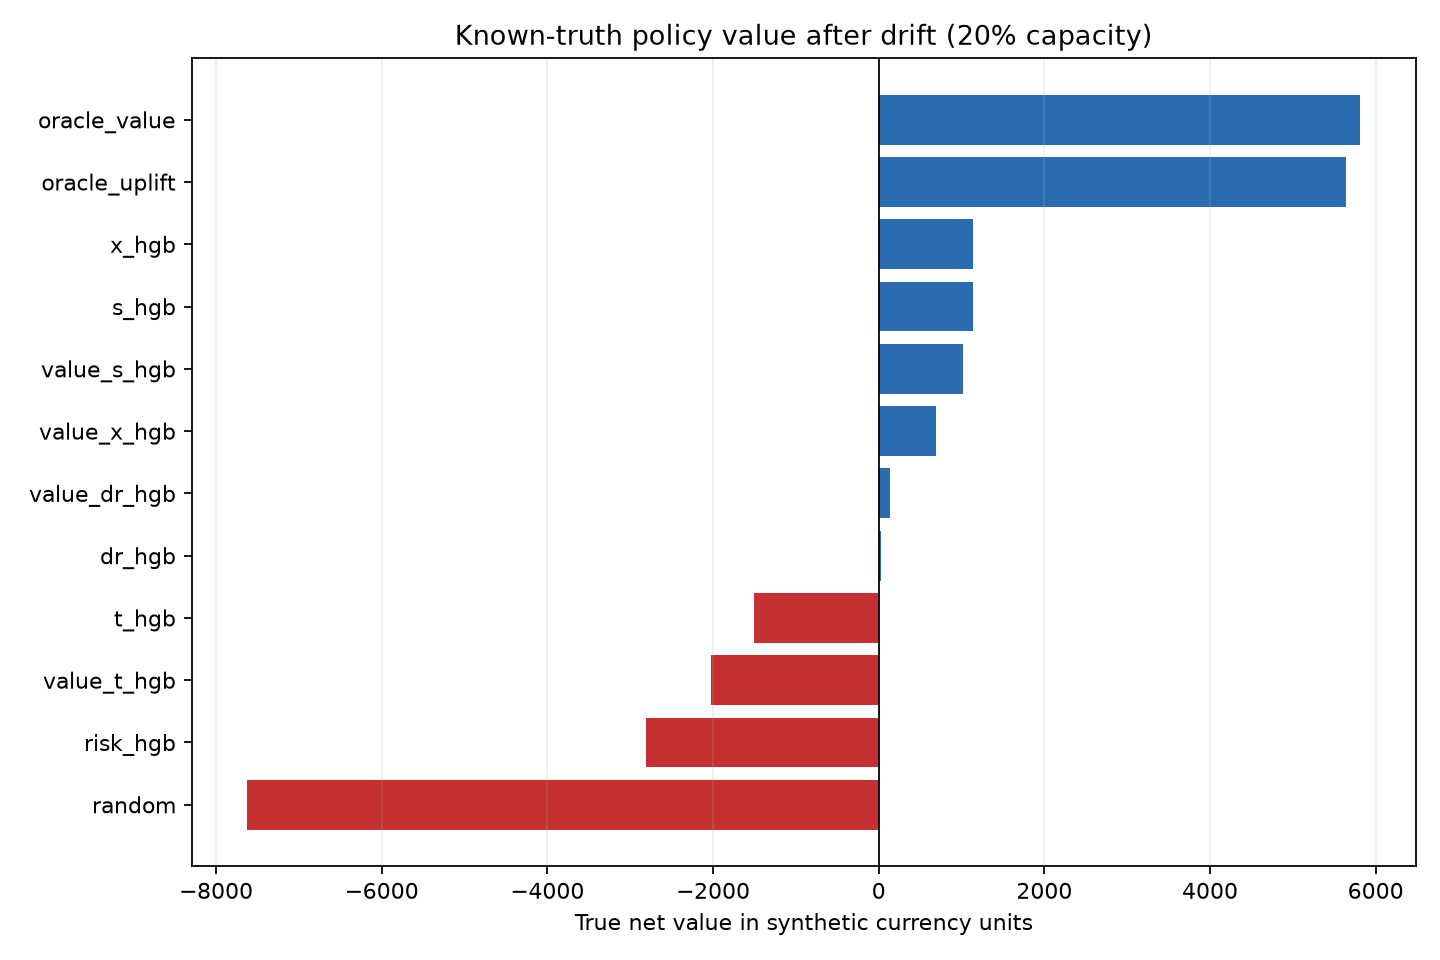

In [8]:
test = pd.read_csv(REPORT / "test_policy_truth.csv")
at_20 = test[test["budget_fraction"].eq(0.20)].sort_values("true_net_value", ascending=False)
display(at_20[["policy", "selected_n", "true_net_value", "true_expected_churns_prevented",
               "harmful_offer_share", "regret_vs_oracle_value"]])
display(Image(filename=str(REPORT / "figures/test_policy_value_at_20pct.png")))

## 8. CATE recovery không đồng nghĩa policy value

In [9]:
display(pd.read_csv(REPORT / "test_cate_diagnostics.csv").sort_values("pehe"))

,model,pehe,cate_bias,spearman_with_true_cate
3,x_hgb,0.019392,0.001808,0.507797
1,s_hgb,0.019867,0.002469,0.409153
2,dr_hgb,0.021665,0.002221,0.402999
0,t_hgb,0.025587,0.002948,0.380855


## 9. Continuous rolling decision

In [10]:
rolling = pd.read_csv(REPORT / "rolling_backtest.csv")
display(rolling)

,month_index,snapshot_month,training_rows,active_customers,selected_n,true_net_value,oracle_net_value,regret,true_mean_cate,harmful_offer_share
0,15,2025-04-01,70980,3246,0,0.0,2760.240089,2760.240089,0.0,0.0
1,16,2025-05-01,74226,3057,0,0.0,2013.775788,2013.775788,0.0,0.0
2,17,2025-06-01,77283,2874,0,0.0,2032.418820,2032.418820,0.0,0.0


## 10. Kết luận đúng phạm vi

- Ground truth chứng minh được risk targeting có thể âm sau effect drift và một uplift learner có thể
  giảm harmful contacts ở cùng capacity.
- Gate bảo thủ tránh expected loss nhưng có opportunity cost; cần persistent exploration và power lớn hơn
  để học segment hiệu quả, không nên tắt control.
- Thứ tự S/T/DR ở DGP này không phải leaderboard chung.
- Muốn claim thực tế phải thay generator bằng governed customer-month data, treatment assignment,
  delivery/cost/margin và future holdout từ doanh nghiệp.